# **Logistic Regression baseline for Salama**

We want to compare our DistilBERT models against Logistic Regression to demonstrate whether transformer-based models actually improves GBV classification as compared with a traditional machine-learning approach.

In [1]:
# Importing the necessary libraries
import pandas as pd
import numpy as np

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [5]:
# Loading the datasets
train_gbv = pd.read_csv("../../data/train_consensus.csv")
dev_gbv = pd.read_csv("../../data/development.csv")


In [6]:
train_gbv.shape

(4181, 3)

In [7]:
dev_gbv.shape

(420, 3)

In [9]:
train_gbv.columns

Index(['question_id', 'question_text', 'final_labels'], dtype='str')

In [10]:
dev_gbv.columns

Index(['question_id', 'question_text', 'final_labels'], dtype='str')

Confirming which columns contain the narratives and GBV labels.

In [11]:
# Preview the training dataset
display(train_gbv.head(3))

# Preview the development dataset
display(dev_gbv.head(3))

,question_id,question_text,final_labels
0,Question 1,Title: Workplace Sexual Harassment while WFH\n...,no_crisis
1,Question 2,Title: I’m scared\n\nText: I don’t know what t...,domesticviolence_ongoing
2,Question 3,Title: Is my supervisor harassing me?\n\nText:...,sexualharassment_ongoing


,question_id,question_text,final_labels
0,Question 1,Title: I miss him like crazy.\n\nText: In earl...,domesticviolence_past
1,Question 2,Title: Victims and tenant/landlord issues\n\nT...,domesticviolence_past
2,Question 3,Title: I was witness to what I think was domes...,No crisis


Inspecting the labels on both datasets to reproduce the same binary classification setup used during DistilBERT training.

In [14]:
print("Training labels:")
print(train_gbv["final_labels"].value_counts(dropna=False))

print("\nDevelopment labels:")
print(dev_gbv["final_labels"].value_counts(dropna=False))

Training labels:
final_labels
no_crisis                                                                         1160
selfharm_ongoing                                                                   558
suicideideation_passive_ongoing                                                    438
suicideideation_active_ongoing                                                     365
domesticviolence_past                                                              230
                                                                                  ... 
domesticviolence_ongoing, rape_past                                                  1
sexualharassment_past, rape_past                                                     1
sexualharassment_ongoing, sexualharassment_past                                      1
suicideideation_active_ongoing, childabuse_endangerment_past, selfharm_ongoing       1
suicideideation_active_past, suicideideation_active_ongoing                          1
Name: count, 

There are differences in some labels: Training dataset uses `no_crisis` while development uses `No crisis`.

There's also: `childabuse_endangerment` in the training dataset while development uses `childabuseendangerment`

**Standardizing the column names**

In [15]:
train_gbv.columns = train_gbv.columns.str.strip().str.lower()
dev_gbv.columns = dev_gbv.columns.str.strip().str.lower()

print("Training columns:", train_gbv.columns.tolist())
print("Development columns:", dev_gbv.columns.tolist())

Training columns: ['question_id', 'question_text', 'final_labels']
Development columns: ['question_id', 'question_text', 'final_labels']


**Inspecting narratives for annotations**

In [17]:
print("TRAINING NARRATIVE")
print(train_gbv["question_text"].iloc[1])

print("\n" + "=" * 70 + "\n")

print("DEVELOPMENT NARRATIVE")
print(dev_gbv["question_text"].iloc[0])

TRAINING NARRATIVE
Title: I’m scared

Text: I don’t know what to do anymore. I am terrified. I got a beer bottle broken in my face tonight. He then took our one year old daughter and locked himself in the room with her. I’m a recovering addict (3years sober) but he continues to use my past against me.. my family adores him! We don’t have many resources where I live, but even with resources.. I don’t want to leave him. I feel like I’m the “bad guy” somehow. I’m a stay at home mom and I’m afraid if I call the cops, they’ll just take my daughter since I don’t have an income! He insists that I don’t work, he wants me home with our daughter. But it’s been getting worse and worse. Idk what to do. I’m literally afraid for my life if I try to leave. I just need some advice! Please!!

For any crisis present, mark whether it is Ongoing or Past. 
**Leave a row blank if that crisis type is not present.**


DEVELOPMENT NARRATIVE
Title: I miss him like crazy.

Text: In early May, my (now) ex-boyfrie

In [ ]:
# Checking how many narratives have the annotation
annotation = r"leave a row blank if that crisis type is not present"

print(
    "Training:",
    train_gbv["question_text"].str.contains(
        annotation, case=False, na=False, regex=True
    ).sum()
)

print(
    "Development:",
    dev_gbv["question_text"].str.contains(
        annotation, case=False, na=False, regex=True
    ).sum()
)

Training: 4181
Development: 420


In [ ]:
# Removing the annotation instruction
import re

annotation_pattern = (
    r"(?i)leave\s+a\s+row\s+blank\s+"
    r"if\s+that\s+crisis\s+type\s+is\s+not\s+present"
)

for df in [train_gbv, dev_gbv]:
    df["question_text"] = (
        df["question_text"]
        .str.replace(annotation_pattern, "", regex=True)
        .str.strip()
    )

# Confirm removal
print(
    "Training remaining:",
    train_gbv["question_text"].str.contains(
        annotation_pattern, na=False, regex=True
    ).sum()
)

print(
    "Development remaining:",
    dev_gbv["question_text"].str.contains(
        annotation_pattern, na=False, regex=True
    ).sum()
)

Training remaining: 0
Development remaining: 0


In [20]:
# Confirming whether any annotation text remains
# Inspect the end of the cleaned narratives
print("TRAINING NARRATIVE END:")
print(repr(train_gbv["question_text"].iloc[1][-600:]))

print("\nDEVELOPMENT NARRATIVE END:")
print(repr(dev_gbv["question_text"].iloc[0][-600:]))

TRAINING NARRATIVE END:
'ober) but he continues to use my past against me.. my family adores him! We don’t have many resources where I live, but even with resources.. I don’t want to leave him. I feel like I’m the “bad guy” somehow. I’m a stay at home mom and I’m afraid if I call the cops, they’ll just take my daughter since I don’t have an income! He insists that I don’t work, he wants me home with our daughter. But it’s been getting worse and worse. Idk what to do. I’m literally afraid for my life if I try to leave. I just need some advice! Please!!\n\nFor any crisis present, mark whether it is Ongoing or Past. \n**.**'

DEVELOPMENT NARRATIVE END:
"my future again, and am looking forward to the next step. There is no worry on my end that I'll get back together with him but I guess I'm still grieving the life we had and the future we planned. Hopefully, I will never see or speak to him ever again because it's what's best for me. I just miss him so damn much. I wish things could have b

In [21]:
# Remove remaining annotation instructions and formatting
annotation_pattern = (
    r"(?i)For any crisis present,\s*"
    r"mark whether it is Ongoing or Past\.\s*"
    r"\*\*\.\*\*"
)

for df in [train_gbv, dev_gbv]:
    df["question_text"] = (
        df["question_text"]
        .str.replace(annotation_pattern, "", regex=True)
        .str.strip()
    )

# Verify cleaning
print("TRAINING NARRATIVE END:")
print(repr(train_gbv["question_text"].iloc[1][-250:]))

print("\nDEVELOPMENT NARRATIVE END:")
print(repr(dev_gbv["question_text"].iloc[0][-250:]))

TRAINING NARRATIVE END:
'e my daughter since I don’t have an income! He insists that I don’t work, he wants me home with our daughter. But it’s been getting worse and worse. Idk what to do. I’m literally afraid for my life if I try to leave. I just need some advice! Please!!'

DEVELOPMENT NARRATIVE END:
"e. I just miss him so damn much. I wish things could have been different. I wish I could have told him that I loved him one last time. I wish it wasn't this hard. \n\nAnyway, I've just been missing him and needed to vent a little. Thanks for listening."


In [22]:
# Standardizing the final labels
def standardize_labels(label):
    if pd.isna(label):
        return label

    label = str(label).strip().lower()

    # Standardize no-crisis labels
    label = label.replace("no crisis", "no_crisis")

    # Standardize child abuse labels
    label = label.replace(
        "childabuseendangerment",
        "childabuse_endangerment"
    )

    # Standardize suicide ideation labels
    label = label.replace(
        "suicideideation(passive)",
        "suicideideation_passive"
    )
    label = label.replace(
        "suicideideation(active)",
        "suicideideation_active"
    )

    # Standardize comma-separated labels
    label = ", ".join(
        part.strip() for part in label.split(",")
    )

    return label


train_gbv["final_labels"] = train_gbv["final_labels"].apply(
    standardize_labels
)

dev_gbv["final_labels"] = dev_gbv["final_labels"].apply(
    standardize_labels
)

# Verify standardization
print("Training labels:")
print(train_gbv["final_labels"].value_counts().head(10))

print("\nDevelopment labels:")
print(dev_gbv["final_labels"].value_counts().head(10))

Training labels:
final_labels
no_crisis                          1160
selfharm_ongoing                    558
suicideideation_passive_ongoing     438
suicideideation_active_ongoing      365
domesticviolence_past               230
rape_past                           225
domesticviolence_ongoing            191
selfharm_past                       187
sexualharassment_ongoing            182
sexualharassment_past               128
Name: count, dtype: int64

Development labels:
final_labels
no_crisis                          134
suicideideation_passive_ongoing     44
selfharm_ongoing                    44
suicideideation_active_ongoing      36
rape_past                           27
selfharm_past                       26
domesticviolence_ongoing            23
domesticviolence_past               19
sexualharassment_ongoing            16
sexualharassment_past               14
Name: count, dtype: int64


**Filtering out the `no_crisis` label and create binary GBV labels**

In [23]:
# GBV categories
gbv_categories = [
    "domesticviolence",
    "rape",
    "sexualharassment",
    "childabuse_endangerment"
]

# Remove no-crisis records
train_binary = train_gbv[
    train_gbv["final_labels"] != "no_crisis"
].copy()

dev_binary = dev_gbv[
    dev_gbv["final_labels"] != "no_crisis"
].copy()

# Create binary GBV target
def create_gbv_label(labels):
    return int(
        any(category in labels for category in gbv_categories)
    )

train_binary["gbv_label"] = train_binary["final_labels"].apply(
    create_gbv_label
)

dev_binary["gbv_label"] = dev_binary["final_labels"].apply(
    create_gbv_label
)

# Check dataset sizes and class distributions
print("Training shape:", train_binary.shape)
print(train_binary["gbv_label"].value_counts())

print("\nDevelopment shape:", dev_binary.shape)
print(dev_binary["gbv_label"].value_counts())

Training shape: (3021, 4)
gbv_label
0    1763
1    1258
Name: count, dtype: int64

Development shape: (286, 4)
gbv_label
0    166
1    120
Name: count, dtype: int64


Checking for missing narratives and duplicate records

In [24]:
print("Missing narratives:")
print(train_binary["question_text"].isna().sum())

print("\nEmpty narratives:")
print(
    train_binary["question_text"]
    .fillna("")
    .str.strip()
    .eq("")
    .sum()
)

print("\nDuplicate question IDs:")
print(train_binary["question_id"].duplicated().sum())

print("\nDuplicate narratives:")
print(train_binary["question_text"].duplicated().sum())

Missing narratives:
0

Empty narratives:
0

Duplicate question IDs:
0

Duplicate narratives:
2


In [25]:
# Display all records with duplicate narratives
duplicates = train_binary[
    train_binary.duplicated(
        subset=["question_text"],
        keep=False
    )
].sort_values("question_text")

display(
    duplicates[
        ["question_id", "final_labels", "gbv_label"]
    ]
)

print("Total records involved:", len(duplicates))

,question_id,final_labels,gbv_label
754,Question 755,sexualharassment_ongoing,1
2156,Question 2157,sexualharassment_ongoing,1
1635,Question 1636,"suicideideation_active_ongoing, selfharm_ongoing",0
2720,Question 2721,"suicideideation_active_ongoing, selfharm_ongoing",0


Total records involved: 4


Confirmed that both pairs of duplicate narratives have identical labels.

We can safely remvoe one copy of each narrative.

In [26]:
# Remove duplicate narratives from the training dataset
train_binary = train_binary.drop_duplicates(
    subset=["question_text"],
    keep="first"
).reset_index(drop=True)

# Confirm the final dataset sizes
print("Training shape:", train_binary.shape)
print(train_binary["gbv_label"].value_counts())

print("\nDevelopment shape:", dev_binary.shape)
print(dev_binary["gbv_label"].value_counts())

Training shape: (3019, 4)
gbv_label
0    1762
1    1257
Name: count, dtype: int64

Development shape: (286, 4)
gbv_label
0    166
1    120
Name: count, dtype: int64


Now the datasets have the expected sizes as for the DistilBERT. Preparing the narratives for logistic regression.

**TF-IDF(Term Frequency-Inverse Document Frequency) Vectorization**

In [27]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Separate narratives and target labels
X_train = train_binary["question_text"]
y_train = train_binary["gbv_label"]

X_dev = dev_binary["question_text"]
y_dev = dev_binary["gbv_label"]

# Initialize TF-IDF
tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

# Fit only on training data
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform development data using the same vocabulary
X_dev_tfidf = tfidf.transform(X_dev)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Development TF-IDF shape:", X_dev_tfidf.shape)

Training TF-IDF shape: (3019, 10000)
Development TF-IDF shape: (286, 10000)


- max_features=10000: Retains up to 10,000 vocabulary features.
- ngram_range=(1, 2): Captures individual words and two-word phrases, such as domestic violence.
- min_df=2: Excludes terms appearing in fewer than two training narratives.
- sublinear_tf=True: Reduces the influence of repeated words.

**Training the Logistic Regression binary classifier**

In [28]:
from sklearn.linear_model import LogisticRegression

# Initialize the model
lr_binary = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model
lr_binary.fit(X_train_tfidf, y_train)

# Generate predictions on development data
y_dev_pred = lr_binary.predict(X_dev_tfidf)

print("Logistic Regression training completed!")
print("Development predictions:", len(y_dev_pred))

Logistic Regression training completed!
Development predictions: 286


**Evaluating Logistic Regression on the development dataset**

In [29]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Accuracy
print("Development Accuracy:", accuracy_score(y_dev, y_dev_pred))

# Classification report
print("\nClassification Report:")
print(
    classification_report(
        y_dev,
        y_dev_pred,
        target_names=["Non-GBV", "GBV"]
    )
)

# Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_dev, y_dev_pred))

Development Accuracy: 0.9405594405594405

Classification Report:
              precision    recall  f1-score   support

     Non-GBV       0.94      0.96      0.95       166
         GBV       0.94      0.92      0.93       120

    accuracy                           0.94       286
   macro avg       0.94      0.94      0.94       286
weighted avg       0.94      0.94      0.94       286


Confusion Matrix:
[[159   7]
 [ 10 110]]


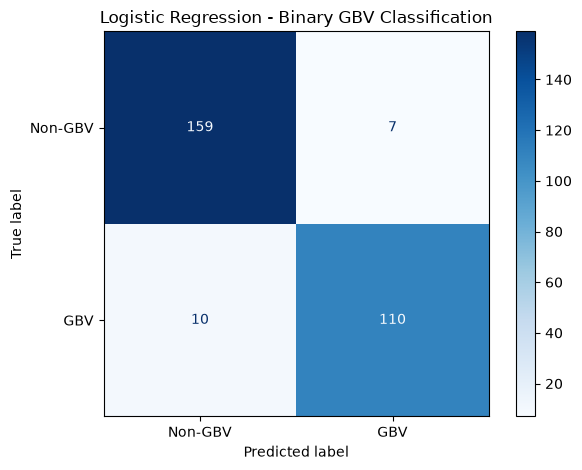

In [30]:
# Visualizing the confusion matrix
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_dev,
    y_dev_pred,
    display_labels=["Non-GBV", "GBV"],
    cmap="Blues",
    values_format="d"
)

plt.title("Logistic Regression - Binary GBV Classification")
plt.tight_layout()
plt.show()

DistilBERT achieved 97.20% development accuracy, compared with 94.06% for Logistic Regression. This suggests that DistilBERT performs better on the development dataset, although a final comparison using the same held-out test data and consistent preprocessing is still required.

# **Multi-label Logistic Regression**

In [31]:
# Creating the multilabel targets
# GBV categories
gbv_categories = [
    "domesticviolence",
    "rape",
    "sexualharassment",
    "childabuse_endangerment"
]

# Create multilabel targets
for category in gbv_categories:
    train_binary[category] = (
        train_binary["final_labels"]
        .str.contains(category, regex=False)
        .astype(int)
    )

    dev_binary[category] = (
        dev_binary["final_labels"]
        .str.contains(category, regex=False)
        .astype(int)
    )

# Separate multilabel targets
y_train_multi = train_binary[gbv_categories]
y_dev_multi = dev_binary[gbv_categories]

# Check category distributions
print("Training category counts:")
print(y_train_multi.sum())

print("\nDevelopment category counts:")
print(y_dev_multi.sum())

Training category counts:
domesticviolence           500
rape                       407
sexualharassment           373
childabuse_endangerment    182
dtype: int64

Development category counts:
domesticviolence           45
rape                       41
sexualharassment           33
childabuse_endangerment     8
dtype: int64


In [33]:
# Training the model
from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression

# Initialize multilabel Logistic Regression
lr_multilabel = OneVsRestClassifier(
    LogisticRegression(
        max_iter=1000,
        random_state=42
    )
)

# Train the model
lr_multilabel.fit(X_train_tfidf, y_train_multi)

# Predict on development data
y_dev_multi_pred = lr_multilabel.predict(X_dev_tfidf)


print("Prediction shape:", y_dev_multi_pred.shape)

Prediction shape: (286, 4)


In [34]:
# Evaluating the model
from sklearn.metrics import classification_report, f1_score

# Classification report for each GBV category
print("Multilabel Classification Report:\n")

print(
    classification_report(
        y_dev_multi,
        y_dev_multi_pred,
        target_names=gbv_categories,
        zero_division=0
    )
)

# Overall F1-scores
print(
    "Micro F1-score:",
    f1_score(y_dev_multi, y_dev_multi_pred, average="micro")
)

print(
    "Macro F1-score:",
    f1_score(y_dev_multi, y_dev_multi_pred, average="macro")
)

Multilabel Classification Report:

                         precision    recall  f1-score   support

       domesticviolence       1.00      0.47      0.64        45
                   rape       1.00      0.22      0.36        41
       sexualharassment       1.00      0.42      0.60        33
childabuse_endangerment       0.00      0.00      0.00         8

              micro avg       1.00      0.35      0.51       127
              macro avg       0.75      0.28      0.40       127
           weighted avg       0.94      0.35      0.50       127
            samples avg       0.15      0.15      0.15       127

Micro F1-score: 0.5146198830409356
Macro F1-score: 0.39802707930367504


The model has high precision and low recall meaning that when it's predicting a GBV category, it is usually correct but misses many actual cases.

In [35]:
# Checking the predicted probabilities
import pandas as pd

# Get predicted probabilities for each GBV category
y_dev_multi_proba = lr_multilabel.predict_proba(X_dev_tfidf)

# Convert probabilities into a DataFrame
proba_df = pd.DataFrame(
    y_dev_multi_proba,
    columns=gbv_categories
)

# Examine probability distributions
print("Predicted probability summary:")
display(proba_df.describe().round(3))

# Count predictions above the default threshold
print("\nPredictions above 0.5:")
print((proba_df >= 0.5).sum())

Predicted probability summary:


,domesticviolence,rape,sexualharassment,childabuse_endangerment
count,286.000,286.000,286.000,286.000
mean,0.169,0.131,0.118,0.063
std,0.181,0.131,0.143,0.052
min,0.024,0.025,0.017,0.014
25%,0.059,0.053,0.039,0.031
50%,0.095,0.075,0.062,0.043
75%,0.184,0.152,0.119,0.077
max,0.894,0.726,0.757,0.387



Predictions above 0.5:
domesticviolence           21
rape                        9
sexualharassment           14
childabuse_endangerment     0
dtype: int64


The model is being very conservative. It only predicts a category when its estimated probability reaches 50%.

In [36]:
# Examine probabilities for actual positive cases
for i, category in enumerate(gbv_categories):

    actual_positive_probs = y_dev_multi_proba[
        y_dev_multi[category].to_numpy() == 1,
        i
    ]

    print(f"\n{category}")
    print(f"Actual positive cases: {len(actual_positive_probs)}")
    print(f"Mean probability: {actual_positive_probs.mean():.3f}")
    print(f"Minimum probability: {actual_positive_probs.min():.3f}")
    print(f"Maximum probability: {actual_positive_probs.max():.3f}")


domesticviolence
Actual positive cases: 45
Mean probability: 0.515
Minimum probability: 0.163
Maximum probability: 0.894

rape
Actual positive cases: 41
Mean probability: 0.378
Minimum probability: 0.046
Maximum probability: 0.726

sexualharassment
Actual positive cases: 33
Mean probability: 0.425
Minimum probability: 0.101
Maximum probability: 0.757

childabuse_endangerment
Actual positive cases: 8
Mean probability: 0.161
Minimum probability: 0.099
Maximum probability: 0.267


In [37]:
# Evaluating the classification threholds

thresholds = np.arange(0.10, 0.55, 0.05)

results = []

for threshold in thresholds:

    predictions = (y_dev_multi_proba >= threshold).astype(int)

    results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(
            y_dev_multi, predictions,
            average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_dev_multi, predictions,
            average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_dev_multi, predictions,
            average="macro", zero_division=0
        )
    })

threshold_results = pd.DataFrame(results)

display(threshold_results.round(3))

,Threshold,Precision,Recall,Macro F1
0,0.10,0.301,0.963,0.453
1,0.15,0.445,0.871,0.585
2,0.20,0.563,0.694,0.618
3,0.25,0.668,0.644,0.642
4,0.30,0.640,0.542,0.583
5,0.35,0.664,0.472,0.547
6,0.40,0.723,0.417,0.520
7,0.45,0.734,0.348,0.460
8,0.50,0.750,0.278,0.398


The results show that lowering the classification threshold significantly improves Logistic Regression's multilabel performance.

But since we have four different categories, we cannot use the same threshold for all of them.

In [38]:
# Finding the best threshold for each category
threshold_grid = np.arange(0.05, 0.55, 0.05)

best_thresholds = {}

for i, category in enumerate(gbv_categories):

    y_true = y_dev_multi[category].to_numpy()
    probabilities = y_dev_multi_proba[:, i]

    scores = []

    for threshold in threshold_grid:
        predictions = (probabilities >= threshold).astype(int)

        score = f1_score(
            y_true,
            predictions,
            zero_division=0
        )

        scores.append(score)

    best_index = np.argmax(scores)

    best_thresholds[category] = round(
        float(threshold_grid[best_index]), 2
    )

    print(
        f"{category}: "
        f"Threshold = {best_thresholds[category]}, "
        f"F1 = {scores[best_index]:.3f}"
    )

domesticviolence: Threshold = 0.3, F1 = 0.857
rape: Threshold = 0.2, F1 = 0.809
sexualharassment: Threshold = 0.25, F1 = 0.769
childabuse_endangerment: Threshold = 0.15, F1 = 0.312


In [39]:
# Evaluating the tuned multilabel classification model by applying category-specific thresholds
y_dev_multi_tuned = np.column_stack([
    (
        y_dev_multi_proba[:, i] >= best_thresholds[category]
    ).astype(int)
    for i, category in enumerate(gbv_categories)
])

# Classification report
print("Tuned Multilabel Logistic Regression:\n")

print(
    classification_report(
        y_dev_multi,
        y_dev_multi_tuned,
        target_names=gbv_categories,
        zero_division=0
    )
)

# Overall F1-scores
print(
    "\nMicro F1-score:",
    f1_score(
        y_dev_multi,
        y_dev_multi_tuned,
        average="micro"
    )
)

print(
    "Macro F1-score:",
    f1_score(
        y_dev_multi,
        y_dev_multi_tuned,
        average="macro"
    )
)

Tuned Multilabel Logistic Regression:

                         precision    recall  f1-score   support

       domesticviolence       0.85      0.87      0.86        45
                   rape       0.75      0.88      0.81        41
       sexualharassment       0.78      0.76      0.77        33
childabuse_endangerment       0.21      0.62      0.31         8

              micro avg       0.70      0.83      0.76       127
              macro avg       0.65      0.78      0.69       127
           weighted avg       0.76      0.83      0.78       127
            samples avg       0.30      0.35      0.31       127


Micro F1-score: 0.7581227436823105
Macro F1-score: 0.6869655976046425


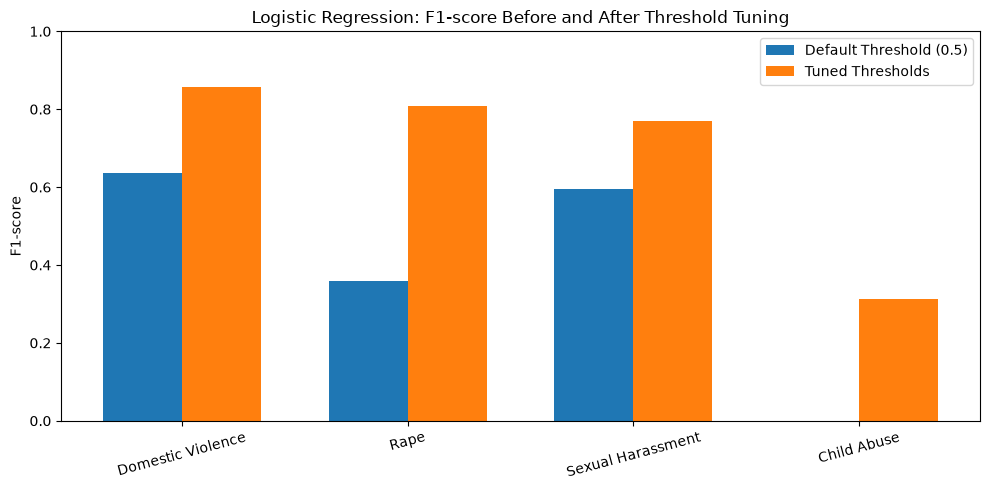

In [40]:
default_f1 = f1_score(
    y_dev_multi,
    y_dev_multi_pred,
    average=None,
    zero_division=0
)

tuned_f1 = f1_score(
    y_dev_multi,
    y_dev_multi_tuned,
    average=None,
    zero_division=0
)

x = np.arange(len(gbv_categories))
width = 0.35

plt.figure(figsize=(10, 5))

plt.bar(
    x - width / 2,
    default_f1,
    width,
    label="Default Threshold (0.5)"
)

plt.bar(
    x + width / 2,
    tuned_f1,
    width,
    label="Tuned Thresholds"
)

plt.xticks(
    x,
    ["Domestic Violence", "Rape", "Sexual Harassment", "Child Abuse"],
    rotation=15
)

plt.ylabel("F1-score")
plt.title("Logistic Regression: F1-score Before and After Threshold Tuning")
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()

### Multilabel Logistic Regression – Model Evaluation

A multilabel Logistic Regression model was trained using **TF-IDF features and OneVsRestClassifier** to identify four GBV categories: domestic violence, rape, sexual harassment, and child abuse/endangerment.

The model was evaluated on 286 development narratives.

#### Initial Model Performance

Using the default classification threshold of 0.5, the model achieved:

- **Micro F1-score:** 0.5146
- **Macro F1-score:** 0.3980

The model demonstrated high precision but low recall, indicating that it missed many actual GBV cases. It also failed to identify any child abuse/endangerment cases.

#### Threshold Tuning

Category-specific thresholds were selected using the development dataset to improve the balance between precision and recall.

| GBV Category | Selected Threshold | Tuned F1-score |
|---|---:|---:|
| Domestic Violence | 0.30 | 0.857 |
| Rape | 0.20 | 0.809 |
| Sexual Harassment | 0.25 | 0.769 |
| Child Abuse/Endangerment | 0.15 | 0.312 |

After threshold tuning, the model achieved:

- **Micro F1-score:** 0.7581
- **Macro F1-score:** 0.6870

The macro F1-score improved from **39.80% to 68.70%**, demonstrating that adjusting classification thresholds substantially improved the model's ability to identify GBV categories.

#### Comparison with DistilBERT

The threshold-tuned Logistic Regression model achieved a macro F1-score of **0.6870**, compared with **0.7843 for the threshold-tuned DistilBERT model** on the development dataset.

DistilBERT therefore demonstrated stronger development-set performance, particularly in capturing patterns that the TF-IDF-based Logistic Regression model may struggle to identify.